# Bài 15: Bộ Tự Mã hóa (Autoencoders) và Phát hiện Bất thường trên Ảnh (Anomaly Detection)

## 1. Mục tiêu học tập
- Hiểu bài toán **Visual Anomaly Detection (Phát hiện bất thường trên ảnh)**: Huấn luyện mô hình **chỉ sử dụng các mẫu bình thường (`Normal / Defect-free samples`, `label = 0`)** và phát hiện các mẫu lỗi mới lạ (`Anomalous samples`, `label = 1`) lúc kiểm tra.
- Thực hành cả 3 nhóm phương pháp tiêu biểu:
  1. **Phương pháp ML truyền thống**: `Isolation Forest` và `One-Class SVM` trên vector đặc trưng ảnh.
  2. **Phương pháp Học sâu Tái tạo (`Reconstruction-based`)**: Huấn luyện thực tế **`Convolutional Autoencoder (ConvAutoencoder)`** để vừa phân loại ảnh lỗi (Image-level Anomaly Score) vừa khoanh vùng đúng vết xước/đốm lỗi trên bề mặt (Pixel-level Anomaly Map).
  3. **Phương pháp Nhúng vùng cục bộ (`Patch/Embedding Memory Bank` kiểu `PaDiM` / `PatchCore`)**: Tổng quan nguyên lý và minh họa đối sánh khoảng cách lân cận.

## 2. Kiến thức cần có
- Đã hoàn thành Bài 06, 10 và 14.

## 3. Thời gian học dự kiến
- Khoảng **2.0 – 2.5 giờ** (ước tính).

## 4. Bài toán thực tế đơn giản
Trên dây chuyền kiểm tra vòng đệm kim loại, bạn có hàng nghìn bức ảnh sản phẩm lành lặn nhưng hầu như chưa có mẫu lỗi, hoặc lỗi trong tương lai có thể là vết xước, vết mẻ, đốm gỉ sét bất kỳ. Ta huấn luyện `ConvAutoencoder` học cách nén và vẽ lại sản phẩm lành lặn; khi gặp sản phẩm có vết xước, Autoencoder sẽ vẽ lại bản lành lặn nên hiệu số $|x - \hat{x}|$ sẽ làm lộ rõ vị trí vết xước!

## 5. Giải thích trực quan: Cơ chế Nút cổ chai (`Latent Bottleneck`) của Autoencoder
```
Ảnh đầu vào x (3, 48, 48) ──► [Encoder Conv] ──► Nút cổ chai z (latent_dim = 24) ──► [Decoder ConvTranspose] ──► Ảnh tái tạo x_hat (3, 48, 48)
                                                                                                                        │
                                                                    Bản đồ lỗi E(y, x) = mean_channel(|x - x_hat|) ◄────┘
```
- **Tại sao nút cổ chai `latent_dim` không được quá lớn?**: Nếu `latent_dim` quá rộng (hoặc có nối tắt Skip Connection như U-Net), mạng sẽ học hàm đồng nhất $\hat{x} = x$ (sao chép nguyên xi cả vết xước!), làm mất khả năng phát hiện lỗi.

## 6 & 7. Thuật ngữ mới, Tham số & Công thức Điểm Bất thường
| Keyword | Nghĩa tiếng Việt | Nhóm | Định nghĩa, Giá trị chọn & Ảnh hưởng khi Tăng/Giảm |
|---|---|---|---|
| `latent_vector` ($z$) / `latent_dim` | Vector ẩn nút cổ chai | Kiến trúc | Số chiều nén ở giữa Encoder và Decoder (ví dụ `24`). **Giảm `latent_dim` quá nhỏ**: ảnh tái tạo bị mờ nhòe ngay cả trên mẫu lành; **Tăng quá lớn**: mạng tái tạo được cả vết lỗi (giảm độ nhạy). |
| `reconstruction_loss` | Hàm mất mát tái tạo | Huấn luyện | $\mathcal{L}_{\text{recon}} = \frac{1}{CHW}\|x - \hat{x}\|_2^2$ (`MSELoss`) hoặc $\|x - \hat{x}\|_1$ (`L1Loss`). |
| `anomaly_map` & `anomaly_score` | Bản đồ lỗi & Điểm bất thường | Đánh giá | `anomaly_map` $M(y,x) = \frac{1}{C}\sum_c |x_{c,y,x} - \hat{x}_{c,y,x}|$. Điểm toàn ảnh `anomaly_score` thường lấy `max` hoặc phân vị `98%` (`np.percentile(M, 98)`) của `anomaly_map` để nhạy với các vết xước nhỏ! |
| `IsolationForest(contamination)` | Rừng cô lập ngoại lai | Anomaly ML | Cô lập điểm dị biệt bằng các nhát cắt ngẫu nhiên; điểm bất thường cần ít nhát cắt hơn để bị cô lập. |


In [1]:
# Cell 1: Tạo Bộ dữ liệu Kiểm tra Lỗi Bề mặt (Chỉ dùng Ảnh Bình thường để Train!)
import sys
from pathlib import Path

current_dir = Path.cwd().resolve()
project_root = current_dir.parent if current_dir.name == "notebooks" else current_dir
if (project_root / "image_ai_learning").is_dir():
    project_root = project_root / "image_ai_learning"
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.ensemble import IsolationForest
from sklearn.svm import OneClassSVM
from sklearn.metrics import roc_auc_score, average_precision_score

from src.utils import set_seed, get_device, count_parameters, save_checkpoint
from src.synthetic_data import generate_anomaly_dataset
from src.features import extract_combined_features
from src.models import ConvAutoencoder

QUICK_RUN = True
set_seed(42)
device = get_device()

anom_ds = generate_anomaly_dataset(
    num_normal=120 if QUICK_RUN else 240,
    num_anomalous=36 if QUICK_RUN else 60,
    image_size=48,
    seed=42,
)
imgs_np = anom_ds["images"]
labels_np = anom_ds["labels"]          # 0: Normal, 1: Anomaly
defect_masks_np = anom_ds["anomaly_masks"]

normal_indices = np.where(labels_np == 0)[0]
anom_indices = np.where(labels_np == 1)[0]

# Chia tập: Tập Train CHỈ CHỨA MẪU BÌNH THƯỜNG (label = 0)!
# Tập Test chứa phần mẫu bình thường còn lại + toàn bộ mẫu lỗi (label = 1).
n_train_norm = int(len(normal_indices) * 0.75)
idx_tr_norm = normal_indices[:n_train_norm]
idx_te_mix = np.concatenate([normal_indices[n_train_norm:], anom_indices])
y_te_mix = labels_np[idx_te_mix]

print(f"Tập Train (100% Normal): {len(idx_tr_norm)} ảnh | Tập Test hỗn hợp: {len(idx_te_mix)} ảnh (Normal: {(y_te_mix==0).sum()}, Anomaly: {(y_te_mix==1).sum()})")


Tập Train (100% Normal): 90 ảnh | Tập Test hỗn hợp: 66 ảnh (Normal: 30, Anomaly: 36)


In [2]:
# Cell 2: Baseline Phát hiện Bất thường bằng Isolation Forest và One-Class SVM trên Đặc trưng Ảnh
feats_all = extract_combined_features(imgs_np, cell_size=8)
X_tr_f = feats_all[idx_tr_norm]
X_te_f = feats_all[idx_te_mix]

iso_forest = IsolationForest(n_estimators=100, contamination=0.1, random_state=42).fit(X_tr_f)
# decision_function càng nhỏ (càng âm) thì càng bất thường -> đảo dấu để làm anomaly_score
scores_iso = -iso_forest.decision_function(X_te_f)

oc_svm = OneClassSVM(kernel="rbf", nu=0.1, gamma="scale").fit(X_tr_f)
scores_ocsvm = -oc_svm.decision_function(X_te_f)

print(f"Isolation Forest -> ROC-AUC: {roc_auc_score(y_te_mix, scores_iso):.4f} | PR-AUC: {average_precision_score(y_te_mix, scores_iso):.4f}")
print(f"One-Class SVM    -> ROC-AUC: {roc_auc_score(y_te_mix, scores_ocsvm):.4f} | PR-AUC: {average_precision_score(y_te_mix, scores_ocsvm):.4f}")


Isolation Forest -> ROC-AUC: 0.9167 | PR-AUC: 0.9270
One-Class SVM    -> ROC-AUC: 0.9648 | PR-AUC: 0.9811


In [3]:
# Cell 3: Huấn luyện Thực tế Convolutional Autoencoder Chỉ trên Ảnh Bình thường
X_all_t = torch.from_numpy(imgs_np).permute(0, 3, 1, 2).float() / 255.0
train_norm_loader = DataLoader(TensorDataset(X_all_t[idx_tr_norm]), batch_size=16, shuffle=True)

ae_model = ConvAutoencoder(in_channels=3, image_size=48, latent_dim=24).to(device)
print("ConvAutoencoder Parameters:", count_parameters(ae_model))

ae_opt = torch.optim.AdamW(ae_model.parameters(), lr=3e-3, weight_decay=1e-5)
mse_crit = nn.MSELoss()
epochs_ae = 15 if QUICK_RUN else 30

ae_losses = []
for ep in range(1, epochs_ae + 1):
    ae_model.train()
    ep_loss = 0.0
    for (xb,) in train_norm_loader:
        xb = xb.to(device)
        ae_opt.zero_grad()
        recon_b, _ = ae_model(xb)
        loss = mse_crit(recon_b, xb)
        loss.backward()
        ae_opt.step()
        ep_loss += loss.item() * len(xb)
    ae_losses.append(ep_loss / len(idx_tr_norm))

# Tính bản đồ sai số tái tạo (Anomaly Map) trên tập Train Normal (để chọn ngưỡng) và tập Test
ae_model.eval()
with torch.no_grad():
    recon_tr, _ = ae_model(X_all_t[idx_tr_norm].to(device))
    err_map_tr = torch.abs(X_all_t[idx_tr_norm].to(device) - recon_tr).mean(dim=1).cpu().numpy()
    # Dùng phân vị thứ 98 của sai số điểm ảnh trong mỗi ảnh làm điểm bất thường nhạy với vết xước cục bộ
    tr_scores = np.percentile(err_map_tr, 98, axis=(1, 2))
    threshold_95 = float(np.percentile(tr_scores, 95))

    recon_te, _ = ae_model(X_all_t[idx_te_mix].to(device))
    err_map_te = torch.abs(X_all_t[idx_te_mix].to(device) - recon_te).mean(dim=1).cpu().numpy()
    te_scores = np.percentile(err_map_te, 98, axis=(1, 2))

ae_roc_auc = roc_auc_score(y_te_mix, te_scores)
ae_pr_auc = average_precision_score(y_te_mix, te_scores)
preds_ae = (te_scores >= threshold_95).astype(np.int64)
ae_acc = float((preds_ae == y_te_mix).mean())

ckpt_ae = project_root / "outputs" / "checkpoints" / "nb15_conv_autoencoder.pt"
save_checkpoint(
    ckpt_ae, ae_model, class_names=["normal", "anomaly"],
    preprocessing_config={"image_size": 48, "anomaly_threshold": threshold_95},
    epoch=epochs_ae, val_metrics={"roc_auc": float(ae_roc_auc), "pr_auc": float(ae_pr_auc)},
)
print(f"ConvAutoencoder -> Train Recon MSE giảm từ {ae_losses[0]:.4f} xuống {ae_losses[-1]:.4f}")
print(f"ConvAutoencoder Test -> ROC-AUC: {ae_roc_auc:.4f} | PR-AUC: {ae_pr_auc:.4f} | Accuracy (tại ngưỡng {threshold_95:.3f}): {ae_acc*100:.1f}%")


ConvAutoencoder Parameters: {'total': 239883, 'trainable': 239883, 'frozen': 0}
ConvAutoencoder -> Train Recon MSE giảm từ 0.0152 xuống 0.0011
ConvAutoencoder Test -> ROC-AUC: 1.0000 | PR-AUC: 1.0000 | Accuracy (tại ngưỡng 0.064): 93.9%


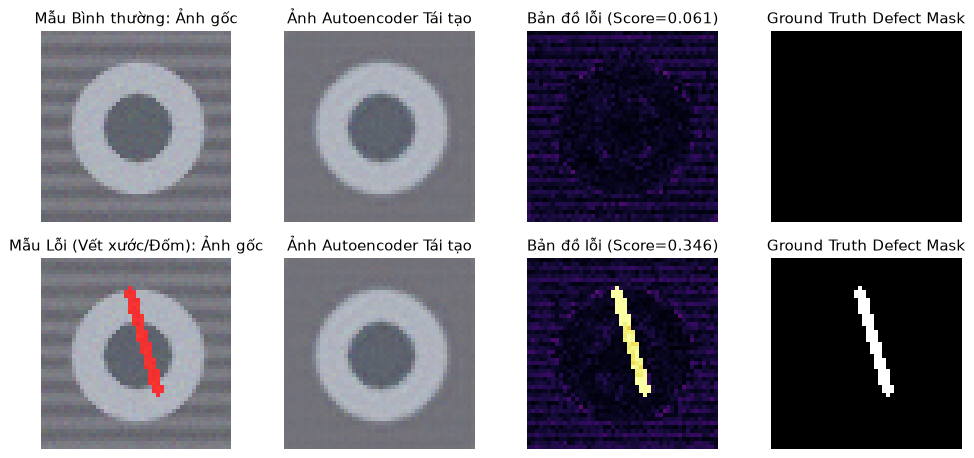

In [4]:
# Cell 4: Trực quan hóa Ảnh Bình thường vs Ảnh Bị Lỗi, Ảnh Tái tạo và Bản đồ Nhiệt Vị trí Lỗi (Anomaly Map)
norm_sample_idx = 0
anom_sample_idx = len(idx_te_mix) - 1  # Mẫu lỗi

fig, axes = plt.subplots(2, 4, figsize=(11, 5.2))
for row, (local_i, row_title) in enumerate([(norm_sample_idx, "Mẫu Bình thường"), (anom_sample_idx, "Mẫu Lỗi (Vết xước/Đốm)")]):
    orig_idx = idx_te_mix[local_i]
    recon_rgb = (recon_te[local_i].permute(1, 2, 0).cpu().numpy() * 255).clip(0, 255).astype(np.uint8)
    axes[row, 0].imshow(imgs_np[orig_idx])
    axes[row, 0].set_title(f"{row_title}: Ảnh gốc")
    axes[row, 1].imshow(recon_rgb)
    axes[row, 1].set_title("Ảnh Autoencoder Tái tạo")
    axes[row, 2].imshow(err_map_te[local_i], cmap="inferno", vmin=0.0, vmax=0.35)
    axes[row, 2].set_title(f"Bản đồ lỗi (Score={te_scores[local_i]:.3f})")
    axes[row, 3].imshow(defect_masks_np[orig_idx], cmap="gray")
    axes[row, 3].set_title("Ground Truth Defect Mask")
    for c in range(4):
        axes[row, c].axis("off")
plt.tight_layout()
plt.show()


## 11. Nhận xét cách đọc kết quả
- **Ở Cell 3 & 4**: Vì `ConvAutoencoder` chỉ học trên các vòng đệm lành lặn, khi gặp mẫu có vết xước đỏ hoặc đốm bẩn xanh ở hàng dưới, ảnh tái tạo của Autoencoder "tự xóa" mất vết xước đó để vẽ lại bề mặt lành lặn. Khi lấy hiệu $|x - \hat{x}|$, bản đồ nhiệt (`Anomaly Map`) bật sáng rực tại đúng tọa độ của vết lỗi, khớp với `Ground Truth Defect Mask`!

## 12 & 14. Thí nghiệm và Bài tập tự làm
- **Cơ bản**: So sánh `ROC-AUC` khi tính `anomaly_score` toàn ảnh bằng trung bình cộng toàn bộ pixel (`err_map_te.mean(axis=(1, 2))`) so với lấy phân vị thứ 98 (`np.percentile(err_map_te, 98, axis=(1, 2))`).
- **Trung cấp**: Khảo sát kích thước nút cổ chai `latent_dim` qua `[4, 24, 128]` để kiểm chứng tác động của độ rộng nút cổ chai lên sai số tái tạo.
- **Nâng cao**: Cài đặt phương pháp **Memory Bank kiểu PatchCore thu nhỏ**: Lưu các vector đặc trưng của ảnh bình thường vào kho bộ nhớ `memory_bank`, với mỗi ảnh kiểm tra mới, tính khoảng cách Euclidean tới lân cận gần nhất trong `memory_bank` làm điểm bất thường!

## 15. Gợi ý và Lời giải


In [5]:
# Cell 5: Lời giải hoàn chỉnh cho bài tập Bài 15
# 1. Cơ bản: So sánh Mean Error Score vs 98th-Percentile Error Score
mean_scores = err_map_te.mean(axis=(1, 2))
print(f"[Cơ bản] Dùng Mean toàn ảnh -> ROC-AUC: {roc_auc_score(y_te_mix, mean_scores):.4f} vs Dùng Percentile-98 -> ROC-AUC: {ae_roc_auc:.4f}")

# 2. Trung cấp: Khảo sát latent_dim
for l_dim in [4, 24, 128]:
    ae_tmp = ConvAutoencoder(3, 48, latent_dim=l_dim)
    print(f"[Trung cấp] latent_dim={l_dim:3d} -> Tổng tham số: {count_parameters(ae_tmp)['total']:,}")

# 3. Nâng cao: Phát hiện bất thường bằng Kho Bộ nhớ Đặc trưng (Memory Bank Nearest-Neighbor kiểu PatchCore)
with torch.no_grad():
    bank_latents = ae_model.encode(X_all_t[idx_tr_norm].to(device)).cpu().numpy()  # (N_train, 24)
    test_latents = ae_model.encode(X_all_t[idx_te_mix].to(device)).cpu().numpy()   # (N_test, 24)

# Khoảng cách tới mẫu bình thường gần nhất trong Memory Bank
dists_matrix = np.linalg.norm(test_latents[:, None, :] - bank_latents[None, :, :], axis=-1)
nn_anomaly_scores = dists_matrix.min(axis=1)
print(f"[Nâng cao] Memory Bank Nearest-Neighbor ROC-AUC: {roc_auc_score(y_te_mix, nn_anomaly_scores):.4f}")


[Cơ bản] Dùng Mean toàn ảnh -> ROC-AUC: 1.0000 vs Dùng Percentile-98 -> ROC-AUC: 1.0000
[Trung cấp] latent_dim=  4 -> Tổng tham số: 55,543
[Trung cấp] latent_dim= 24 -> Tổng tham số: 239,883
[Trung cấp] latent_dim=128 -> Tổng tham số: 1,198,451
[Nâng cao] Memory Bank Nearest-Neighbor ROC-AUC: 1.0000


## 16. Tóm tắt & Điều kiện chuyển bài tiếp theo
- [x] Hiểu nguyên lý phát hiện bất thường một lớp (`One-Class / Unsupervised Anomaly Detection`).
- [x] Đã huấn luyện thực tế `ConvAutoencoder` chỉ với ảnh lành và khoanh vùng được vị trí lỗi.
- [x] Sẵn sàng chuyển sang **Bài 16: `16_metric_learning_and_image_retrieval.ipynb`**.

## 17. Nguồn tham khảo
- Bergmann, P. et al. (2019), *MVTec AD — A Comprehensive Real-World Dataset for Unsupervised Anomaly Detection*, CVPR.
- Roth, K. et al. (2022), *Towards Total Recall in Industrial Anomaly Detection (PatchCore)*, CVPR.
